# E-Commerce Product Recommendation Engine

## Project Objective
Build a personalized e-commerce product recommendation system that recommends relevant products to users based on their historical interactions.

## Key Goals
- Generate and explore synthetic e-commerce interaction data.
- Build a popularity-based recommendation baseline.
- Develop personalized recommendation models.
- Evaluate models using Precision@K, Recall@K, and NDCG@K.
- Analyze cold-start problems and catalog coverage.
- Deploy the recommendation model through an API or user interface.

## Dataset
Synthetic dataset containing users, products, and user-product interactions.

## Reproducibility
Random seed: 42

## How this notebook is organized

Run it top to bottom (Runtime -> Run all). Reusable code lives in `src/` and is written once in Part 2; every later part imports it, so the notebook, `train.py`, the API and the tests all use identical code.

| Part | What it does |
|---|---|
| 1 | Setup: Drive, packages, imports, folders |
| 2 | Write the project modules (`config`, `generate_data`, `split`, `metrics`, `models`, `explain`, `train`, `api`) |
| 3 | Generate the synthetic data |
| 4 | Data quality checks |
| 5 | Exploratory data analysis |
| 6 | Chronological split, leakage checks, cold-start analysis |
| 7 | Popularity baseline (validation) |
| 8 | Personalized models: item-CF and content-based (validation) |
| 9 | Hybrid tuning on validation, with bootstrap CIs |
| 10 | Final one-shot test evaluation |
| 11 | Error analysis and explanations |
| 12 | Training pipeline and saved artifact |
| 13 | Inference API demo |
| 14 | Tests |
| 15 | Packaging: requirements, README, repo files, reproducibility check |

**Rule for the test set:** it is used once, in Part 10. Nothing is tuned after that.

## 1. Setup

Mount Drive, install packages, import libraries and create the project folders.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn scipy joblib fastapi uvicorn httpx requests pytest

In [3]:
# Data processing
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics.pairwise import cosine_similarity

# Utilities
import random
import os
import json
import joblib

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Random state:", RANDOM_STATE)

All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
Random state: 42


In [4]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ecommerce_recommendation_engine"
)

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "models",
    "tests",
    "reports",
    "outputs"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directory created successfully!")

print("\nProject location:")
print(PROJECT_DIR)

print("\nFolder structure:")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_dir():
        print(path.relative_to(PROJECT_DIR))

Project directory created successfully!

Project location:
/content/drive/MyDrive/ecommerce_recommendation_engine

Folder structure:
.pytest_cache
.pytest_cache/v
.pytest_cache/v/cache
api
app
data
data/processed
data/raw
data/raw_backup
models
notebooks
outputs
reports
src
src/__pycache__
tests
tests/__pycache__


## 2. Project modules (single source of truth)

Each cell below writes one file into `src/`. They are written once, here, in dependency order. Later parts import from them instead of redefining anything.

- `config.py`: seed, sizes, split dates, paths
- `generate_data.py`: seeded synthetic data generator
- `split.py`: chronological split helpers
- `metrics.py`: Precision/Recall/NDCG@K, coverage, and the leakage guard in `evaluate`
- `models.py`: popularity, item-CF, content-based and hybrid recommenders (each refuses history from after its cutoff)
- `explain.py`: per-recommendation explanations
- `train.py`: repeatable training pipeline
- `api.py`: FastAPI inference service

In [5]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/config.py
"""Central config: seed, sizes, split dates and paths. Imported by every script."""
from pathlib import Path

SEED = 42

N_USERS = 1500
N_ITEMS = 400
N_DAYS = 90
START_DATE = "2026-01-01"

CATEGORIES = [
    "Electronics", "Fashion", "Home", "Beauty",
    "Sports", "Books", "Toys", "Grocery",
]

# Time split (chronological)
VAL_START = "2026-03-04"
TEST_START = "2026-03-18"
HORIZON_DAYS = 14   # informational only: windows are defined by the explicit start dates above;
                    # test targets run from TEST_START to the end of the data (about 14 days)

# Paths (relative to the repo, so they work in Colab and on any machine)
PROJECT_DIR = Path(__file__).resolve().parent.parent
ROOT = PROJECT_DIR

DATA_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs"
REPORT_DIR = ROOT / "reports"

for d in [DATA_DIR, PROCESSED_DIR, MODEL_DIR, OUTPUT_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/config.py


In [6]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/generate_data.py
"""
Synthetic e-commerce interaction generator.

Why synthetic: no licensing risk, no personal data, and we can deliberately plant
structure (category taste, price sensitivity, long-tail popularity, late-launching
items, late-joining users) so cold-start can actually be tested.

Output (data/raw/):
  users.csv         user_id, signup_date
  items.csv         item_id, category, brand, price, launch_date, title
  interactions.csv  user_id, item_id, event_type, timestamp   (view/click/cart/purchase)
"""
import numpy as np
import pandas as pd
from config import *

BRANDS = ["Aero", "Nova", "Pico", "Zenith", "Kora", "Lumo", "Vanta", "Orbit"]
ADJ = ["Smart", "Classic", "Eco", "Pro", "Mini", "Ultra", "Comfort", "Prime"]

# funnel: P(click|view), P(cart|click), P(purchase|cart)
P_CLICK, P_CART, P_BUY = 0.35, 0.30, 0.45


def make_items(rng):
    cats = rng.choice(CATEGORIES, N_ITEMS)
    base_price = {c: p for c, p in zip(CATEGORIES, [250, 60, 90, 30, 70, 15, 25, 10])}
    price = np.array([base_price[c] * rng.lognormal(0, 0.5) for c in cats]).round(2)
    # ~15% of items launch mid-history -> cold-start items
    launch = np.where(rng.random(N_ITEMS) < 0.15, rng.integers(30, N_DAYS - 10, N_ITEMS), 0)
    titles = [f"{rng.choice(ADJ)} {c} Item {i}" for i, c in enumerate(cats)]
    items = pd.DataFrame({
        "item_id": np.arange(N_ITEMS), "category": cats,
        "brand": rng.choice(BRANDS, N_ITEMS), "price": price,
        "launch_day": launch, "title": titles})
    # long-tail popularity (Zipf-like) -> a few blockbusters, many niche items
    pop = rng.pareto(1.2, N_ITEMS) + 1
    items["_pop"] = pop / pop.sum()
    return items


def make_users(rng):
    # ~15% of users join mid-history -> cold-start users
    signup = np.where(rng.random(N_USERS) < 0.15, rng.integers(30, N_DAYS - 10, N_USERS), 0)
    return pd.DataFrame({"user_id": np.arange(N_USERS), "signup_day": signup})


def generate():
    rng = np.random.default_rng(SEED)
    items, users = make_items(rng), make_users(rng)
    cat_idx = items["category"].map({c: i for i, c in enumerate(CATEGORIES)}).values
    log_price = np.log(items["price"].values)

    rows = []
    for u, signup in zip(users["user_id"], users["signup_day"]):
        # hidden taste: each user likes 1-3 categories strongly + a price preference
        taste = np.full(len(CATEGORIES), 0.05)
        taste[rng.choice(len(CATEGORIES), rng.integers(1, 4), replace=False)] = rng.uniform(1, 3)
        price_pref = rng.normal(np.log(60), 0.8)
        n_sessions = rng.poisson(6) + 1
        for _ in range(n_sessions):
            day = rng.integers(signup, N_DAYS)
            avail = items["launch_day"].values <= day
            score = items["_pop"].values * taste[cat_idx] * np.exp(-0.5 * (log_price - price_pref) ** 2)
            score = np.where(avail, score, 0)
            if score.sum() == 0:
                continue
            k = rng.integers(2, 8)
            picks = rng.choice(N_ITEMS, size=k, replace=False, p=score / score.sum())
            for it in picks:
                t = pd.Timestamp(START_DATE) + pd.Timedelta(days=int(day), seconds=int(rng.integers(0, 86400)))
                rows.append((u, it, "view", t))
                if rng.random() < P_CLICK:
                    rows.append((u, it, "click", t + pd.Timedelta(seconds=30)))
                    if rng.random() < P_CART:
                        rows.append((u, it, "cart", t + pd.Timedelta(minutes=2)))
                        if rng.random() < P_BUY:
                            rows.append((u, it, "purchase", t + pd.Timedelta(minutes=5)))
    inter = pd.DataFrame(rows, columns=["user_id", "item_id", "event_type", "timestamp"])
    inter = inter.sort_values("timestamp").reset_index(drop=True)

    start = pd.Timestamp(START_DATE)
    users["signup_date"] = start + pd.to_timedelta(users.pop("signup_day"), unit="D")
    items["launch_date"] = start + pd.to_timedelta(items.pop("launch_day"), unit="D")
    items = items.drop(columns="_pop")

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    users.to_csv(DATA_DIR / "users.csv", index=False)
    items.to_csv(DATA_DIR / "items.csv", index=False)
    inter.to_csv(DATA_DIR / "interactions.csv", index=False)
    return users, items, inter


if __name__ == "__main__":
    u, i, x = generate()
    print(f"users={len(u)} items={len(i)} interactions={len(x)}")
    print(x["event_type"].value_counts())

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/generate_data.py


In [7]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/split.py
import pandas as pd
from config import VAL_START, TEST_START


def history_before(inter, cutoff):
    """Everything the system would know at prediction time `cutoff`."""
    return inter[inter.timestamp < pd.Timestamp(cutoff)]


def temporal_split(inter):
    """Returns (train_events, val_targets, test_targets). Targets are purchases only."""
    val_s, test_s = pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)
    is_buy = inter.event_type == "purchase"
    train = inter[inter.timestamp < val_s]
    val_t = inter[is_buy & (inter.timestamp >= val_s) & (inter.timestamp < test_s)]
    # no upper bound: test targets run to the end of the data (about 14 days)
    test_t = inter[is_buy & (inter.timestamp >= test_s)]
    return train, val_t, test_t

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/split.py


In [8]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/metrics.py
import numpy as np


def precision_at_k(recs, relevant, k):
    return len(set(recs[:k]) & relevant) / k


def recall_at_k(recs, relevant, k):
    return len(set(recs[:k]) & relevant) / len(relevant)


def ndcg_at_k(recs, relevant, k):
    dcg = sum(1 / np.log2(i + 2) for i, r in enumerate(recs[:k]) if r in relevant)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / idcg


def evaluate(recommend_fn, history, targets, k=10, catalog_size=None, user_subset=None):
    """recommend_fn(user_id, k) -> ranked list of item_ids.
    Ground truth = target purchases minus items the user already bought in history.
    Raises if history is not strictly earlier than the targets (leakage guard)."""
    if len(history) and len(targets) and history.timestamp.max() >= targets.timestamp.min():
        raise ValueError("history overlaps the target period: leakage")

    seen = history[history.event_type == "purchase"].groupby("user_id").item_id.apply(set).to_dict()
    truth = targets.groupby("user_id").item_id.apply(set).to_dict()

    P, R, N, all_recs = [], [], [], set()
    for u, rel in truth.items():
        if user_subset is not None and u not in user_subset:
            continue
        rel = rel - seen.get(u, set())
        if not rel:
            continue
        recs = recommend_fn(u, k)
        all_recs.update(recs)
        P.append(precision_at_k(recs, rel, k))
        R.append(recall_at_k(recs, rel, k))
        N.append(ndcg_at_k(recs, rel, k))

    if not P:   # nothing evaluable: say so explicitly instead of nan + RuntimeWarning
        return {"n_users": 0, f"P@{k}": np.nan, f"R@{k}": np.nan, f"NDCG@{k}": np.nan,
                **({"coverage": np.nan} if catalog_size else {})}

    out = {"n_users": len(P), f"P@{k}": np.mean(P), f"R@{k}": np.mean(R), f"NDCG@{k}": np.mean(N)}
    if catalog_size:
        out["coverage"] = len(all_recs) / catalog_size
    return out

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/metrics.py


In [9]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/models.py
"""Recommenders: popularity baseline, item-CF, content-based and hybrid.
Every model refuses history containing events at/after its cutoff (leakage guard)."""
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# experimental event weights (not learned)
EVENT_WEIGHTS = {"view": 1.0, "click": 2.0, "cart": 3.0, "purchase": 5.0}


class PopularityRecommender:
    """Most-purchased live items, skipping what the user already bought."""

    def fit(self, history, items, cutoff):
        cutoff = pd.Timestamp(cutoff)
        if len(history) and history.timestamp.max() >= cutoff:
            raise ValueError(f"history contains events at/after cutoff {cutoff}: leakage")
        self.cutoff = cutoff

        buys = history[history.event_type == "purchase"]
        counts = buys.item_id.value_counts()
        live = items.loc[items.launch_date <= cutoff, "item_id"].values   # live at prediction time
        self.ranking = (counts.reindex(live).fillna(0)
                        .sort_values(ascending=False, kind="stable").index.tolist())
        self.seen = buys.groupby("user_id").item_id.apply(set).to_dict()
        return self

    def recommend(self, user_id, k=10):
        seen = self.seen.get(user_id, set())
        return [i for i in self.ranking if i not in seen][:k]


class _PersonalizedBase:
    def fit(self, history, items, cutoff, weights=None):
        cutoff = pd.Timestamp(cutoff)
        if len(history) and history.timestamp.max() >= cutoff:
            raise ValueError(f"history contains events at/after cutoff {cutoff}: leakage")
        self.cutoff = cutoff
        w = weights or EVENT_WEIGHTS

        self.items = items.item_id.values
        self.iidx = {it: j for j, it in enumerate(self.items)}
        self.live = (items.launch_date <= cutoff).values

        h = history.assign(w=history.event_type.map(w))
        agg = h.groupby(["user_id", "item_id"]).w.sum().reset_index()
        agg["w"] = np.log1p(agg.w)                       # dampen repeated views
        users = history.user_id.unique()
        self.uidx = {u: i for i, u in enumerate(users)}
        self.X = sparse.csr_matrix(
            (agg.w.values, (agg.user_id.map(self.uidx), agg.item_id.map(self.iidx))),
            shape=(len(users), len(self.items)))

        buys = history[history.event_type == "purchase"]
        self.seen_idx = {u: [self.iidx[i] for i in s]
                         for u, s in buys.groupby("user_id").item_id.apply(set).items()}
        counts = buys.item_id.value_counts()
        self.popscore = np.array([counts.get(i, 0) for i in self.items], dtype=float)

        self.pop = PopularityRecommender().fit(history, items, cutoff)   # cold-start fallback
        self._prepare(items)
        return self

    def recommend(self, user_id, k=10):
        if user_id not in self.uidx:
            return self.pop.recommend(user_id, k)
        s = np.asarray(self._scores(self.X[self.uidx[user_id]]), dtype=float).ravel()
        s[~self.live] = -np.inf
        s[self.seen_idx.get(user_id, [])] = -np.inf
        order = np.lexsort((-self.popscore, -s))         # ties broken by popularity
        recs = [self.items[j] for j in order[:k] if s[j] > 0]
        if len(recs) < k:                                # backfill with popularity
            extra = [i for i in self.pop.recommend(user_id, k + len(recs)) if i not in recs]
            recs += extra[:k - len(recs)]
        return recs


class ItemCFRecommender(_PersonalizedBase):
    def _prepare(self, items):
        self.sim = cosine_similarity(self.X.T.tocsr())
        np.fill_diagonal(self.sim, 0.0)

    def _scores(self, row):
        return row @ self.sim


class ContentBasedRecommender(_PersonalizedBase):
    def _prepare(self, items):
        # price bands and vocabulary learned from items live at the cutoff only
        live_items = items[self.live]
        edges = np.unique(live_items["price"].quantile(np.linspace(0, 1, 7)).values)
        bands = np.digitize(items["price"].values, edges[1:-1])

        text = ("cat_" + items["category"].astype(str)
                + " brand_" + items["brand"].astype(str)
                + " price_" + pd.Series(bands, index=items.index).astype(str))

        vec = TfidfVectorizer(token_pattern=r"\S+")
        vec.fit(text[self.live])
        self.F = vec.transform(text)          # all items, same feature space

    def _scores(self, row):
        profile = row @ self.F
        return (profile @ self.F.T).toarray()


class HybridRecommender:
    """Weighted blend of per-user max-normalized scores from item-CF, content and popularity."""

    def __init__(self, cf, cb, w_cb=0.25, w_pop=0.1):
        self.cf, self.cb, self.w_cb, self.w_pop = cf, cb, w_cb, w_pop

    def recommend(self, user_id, k=10):
        cf, cb = self.cf, self.cb
        if user_id not in cf.uidx:
            return cf.pop.recommend(user_id, k)

        cand = cf.live.copy()                                  # live and not already bought
        cand[cf.seen_idx.get(user_id, [])] = False

        def norm(x):
            x = np.asarray(x, dtype=float).ravel()
            return x / (x[cand].max() + 1e-12) if cand.any() and x[cand].max() > 0 else x * 0

        s = (norm(cf._scores(cf.X[cf.uidx[user_id]]))
             + self.w_cb * norm(cb._scores(cb.X[cb.uidx[user_id]]))
             + self.w_pop * norm(np.log1p(cf.popscore)))
        s[~cand] = -np.inf
        order = np.lexsort((-cf.popscore, -s))
        return [cf.items[j] for j in order[:k] if np.isfinite(s[j])]

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/models.py


In [10]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/explain.py
import numpy as np


def explain(hybrid, items, user_id, item_id, n=3):
    """Explains one hybrid recommendation: per-signal score breakdown, plus the past items
    that drove the item-CF part (the only part attributable to specific past items)."""
    cf, cb = hybrid.cf, hybrid.cb
    meta = items.set_index("item_id")
    r = meta.loc[item_id]
    j = cf.iidx[item_id]
    pop_rank = cf.pop.ranking.index(item_id) + 1 if item_id in cf.pop.ranking else None

    if user_id not in cf.uidx:
        return {"item_id": int(item_id), "title": r.title,
                "reason": "New shopper with no history: showing currently popular items",
                "popularity_rank": pop_rank}

    row = cf.X[cf.uidx[user_id]]
    cand = cf.live.copy()
    cand[cf.seen_idx.get(user_id, [])] = False

    def norm(x):                                   # same normalization the hybrid uses
        x = np.asarray(x, dtype=float).ravel()
        return x / (x[cand].max() + 1e-12) if cand.any() and x[cand].max() > 0 else x * 0

    parts = {
        "item_cf":    norm(cf._scores(row))[j],
        "content":    hybrid.w_cb * norm(cb._scores(cb.X[cb.uidx[user_id]]))[j],
        "popularity": hybrid.w_pop * norm(np.log1p(cf.popscore))[j],
    }
    total = sum(parts.values()) + 1e-12

    dense = row.toarray().ravel()
    contrib = dense * cf.sim[:, j]
    top = [t for t in np.argsort(-contrib)[:n] if contrib[t] > 0]
    cats = meta.loc[cf.items, "category"].values

    return {
        "item_id": int(item_id), "title": r.title, "category": r.category, "price": float(r.price),
        "score_share": {k: round(float(v / total), 2) for k, v in parts.items()},
        "item_cf_driven_by": [{"title": meta.loc[cf.items[t], "title"],
                               "influence": round(float(contrib[t]), 3)} for t in top],
        "category_share_of_your_activity": round(float(dense[cats == r.category].sum() / max(dense.sum(), 1e-9)), 2),
        "popularity_rank": pop_rank,
    }

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/explain.py


In [11]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/train.py
"""Repeatable training pipeline: data -> chronological split -> fit -> test eval -> artifact."""
import json
import joblib
import pandas as pd
from config import *
from metrics import evaluate
from models import (PopularityRecommender, ItemCFRecommender,
                    ContentBasedRecommender, HybridRecommender)

W_CB, W_POP = 1.0, 1.0       # chosen on validation only


def main():
    items = pd.read_csv(DATA_DIR / "items.csv", parse_dates=["launch_date"])
    inter = pd.read_csv(DATA_DIR / "interactions.csv", parse_dates=["timestamp"])

    cutoff = pd.Timestamp(TEST_START)
    history = inter[inter.timestamp < cutoff]
    targets = inter[(inter.event_type == "purchase") & (inter.timestamp >= cutoff)]
    catalog = int((items.launch_date <= cutoff).sum())

    pop = PopularityRecommender().fit(history, items, cutoff)
    cf = ItemCFRecommender().fit(history, items, cutoff)
    cb = ContentBasedRecommender().fit(history, items, cutoff)
    hybrid = HybridRecommender(cf, cb, W_CB, W_POP)

    metrics = {}
    models_to_evaluate = {"popularity": pop, "item_cf": cf, "content": cb, "hybrid": hybrid}
    for name, m in models_to_evaluate.items():
        r = evaluate(m.recommend, history, targets, k=10, catalog_size=catalog)
        metrics[name] = {k: float(v) for k, v in r.items()}
        print(name, {k: round(v, 3) for k, v in metrics[name].items()})

    meta = {"as_of": str(cutoff), "seed": SEED, "w_cb": W_CB, "w_pop": W_POP,
            "n_history_events": int(len(history)), "test_metrics_k10": metrics}
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump({"hybrid": hybrid, "items": items, "meta": meta}, MODEL_DIR / "recommender.joblib")
    (OUTPUT_DIR / "metrics.json").write_text(json.dumps(meta, indent=2))
    print("saved:", MODEL_DIR / "recommender.joblib")


if __name__ == "__main__":
    main()

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/train.py


In [12]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/src/api.py
import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parent))

import joblib
from fastapi import FastAPI, Query

from config import MODEL_DIR
from explain import explain
import models  # noqa: F401  (joblib needs these classes importable to unpickle the artifact)

app = FastAPI(title="E-Commerce Recommendation API", version="1.0")
_ART = {}

LIMITATIONS = ("Decision support only. Trained on synthetic data; favors popular items; "
               "users without interaction history get a popularity fallback; newly launched products can be "
               "recommended from their metadata, but performance on items without interaction history is uncertain; "
               "products not yet launched at the prediction cutoff are excluded. "
               "Recommendations should be reviewed by a human.")


def art():
    if not _ART:
        _ART.update(joblib.load(MODEL_DIR / "recommender.joblib"))   # real saved model, loaded once
    return _ART


@app.get("/health")
def health():
    a = art()
    return {"status": "ok", "model_as_of": a["meta"]["as_of"], "weights":
            {"w_cb": a["meta"]["w_cb"], "w_pop": a["meta"]["w_pop"]}}


@app.get("/recommend/{user_id}")
def recommend(user_id: int, k: int = Query(10, ge=1, le=50)):
    a = art()
    hybrid, items = a["hybrid"], a["items"]
    meta = items.set_index("item_id")
    known = user_id in hybrid.cf.uidx

    recs = []
    for rank, item_id in enumerate(hybrid.recommend(user_id, k), start=1):
        item_id = int(item_id)
        row = meta.loc[item_id]
        recs.append({
            "rank": rank, "item_id": item_id, "title": str(row.title),
            "category": str(row.category), "price": float(row.price),
            "explanation": explain(hybrid, items, user_id, item_id),
        })
    return {
        "user_id": user_id,
        "strategy": "hybrid" if known else "popularity_fallback",
        "known_user": known,
        "model_as_of": a["meta"]["as_of"],
        "recommendations": recs,
        "limitations": LIMITATIONS,
    }

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/src/api.py


In [13]:
!ls /content/drive/MyDrive/ecommerce_recommendation_engine/src

api.py	   explain.py	     metrics.py  __pycache__  train.py
config.py  generate_data.py  models.py	 split.py


## 3. Generate the synthetic data

The generator is seeded (42), so every run produces identical CSVs in `data/raw/`.

In [14]:
import sys, importlib

SRC = "/content/drive/MyDrive/ecommerce_recommendation_engine/src"
if SRC not in sys.path:
    sys.path.append(SRC)

from config import *
from generate_data import generate

In [15]:
# Generate datasets and store them in notebook variables

users, items, inter = generate()

print("Dataset generation completed!")
print("Users:", users.shape)
print("Items:", items.shape)
print("Interactions:", inter.shape)

Dataset generation completed!
Users: (1500, 2)
Items: (400, 6)
Interactions: (71599, 4)


## 4. Data quality checks

In [16]:
# ============================================
# INITIAL DATA QUALITY CHECKS
# ============================================

print("DATASET SHAPES")
print("-" * 40)

print("Users:", users.shape)
print("Items:", items.shape)
print("Interactions:", inter.shape)


# 1. Missing values
print("\nMISSING VALUES")
print("-" * 40)

print("\nUsers:")
print(users.isnull().sum())

print("\nItems:")
print(items.isnull().sum())

print("\nInteractions:")
print(inter.isnull().sum())


# 2. Duplicate records
print("\nDUPLICATE CHECKS")
print("-" * 40)

print("Duplicate user IDs:", users["user_id"].duplicated().sum())
print("Duplicate item IDs:", items["item_id"].duplicated().sum())

# The generator does not create an event ID.
print("Duplicate interaction rows:", inter.duplicated().sum())


# 3. Referential integrity
print("\nREFERENCE VALIDATION")
print("-" * 40)

invalid_users = (~inter["user_id"].isin(users["user_id"])).sum()
invalid_items = (~inter["item_id"].isin(items["item_id"])).sum()

print("Invalid user references:", invalid_users)
print("Invalid item references:", invalid_items)


# 4. Event types
print("\nEVENT TYPES")
print("-" * 40)

print(inter["event_type"].value_counts())


# 5. Timestamp validation
print("\nTIMESTAMP CHECKS")
print("-" * 40)

print("Earliest interaction:", inter["timestamp"].min())
print("Latest interaction:", inter["timestamp"].max())

print(
    "Interactions sorted chronologically:",
    inter["timestamp"].is_monotonic_increasing
)


# 6. User and item date ranges
print("\nUSER SIGNUP DATES")
print(users["signup_date"].min(), "to", users["signup_date"].max())

print("\nITEM LAUNCH DATES")
print(items["launch_date"].min(), "to", items["launch_date"].max())


# 7. Cold-start simulation checks
print("\nCOLD-START SIMULATION")
print("-" * 40)

print(
    "Late-joining users:",
    (users["signup_date"] > pd.Timestamp(START_DATE)).sum()
)

print(
    "Late-launched items:",
    (items["launch_date"] > pd.Timestamp(START_DATE)).sum()
)

DATASET SHAPES
----------------------------------------
Users: (1500, 2)
Items: (400, 6)
Interactions: (71599, 4)

MISSING VALUES
----------------------------------------

Users:
user_id        0
signup_date    0
dtype: int64

Items:
item_id        0
category       0
brand          0
price          0
title          0
launch_date    0
dtype: int64

Interactions:
user_id       0
item_id       0
event_type    0
timestamp     0
dtype: int64

DUPLICATE CHECKS
----------------------------------------
Duplicate user IDs: 0
Duplicate item IDs: 0
Duplicate interaction rows: 0

REFERENCE VALIDATION
----------------------------------------
Invalid user references: 0
Invalid item references: 0

EVENT TYPES
----------------------------------------
event_type
view        47677
click       16542
cart         5087
purchase     2293
Name: count, dtype: int64

TIMESTAMP CHECKS
----------------------------------------
Earliest interaction: 2026-01-01 00:00:04
Latest interaction: 2026-04-01 00:03:12
Inter

### Initial Data Quality Findings

The generated dataset contains 1,500 users, 400 items, and 71,599 interactions.

The initial validation found:
- No missing values.
- No duplicate user or item IDs.
- No duplicate interaction records.
- No invalid user or item references.
- All interactions are chronologically sorted.

The dataset contains 244 late-joining users and 64 late-launched items, allowing cold-start scenarios to be evaluated.

The simulated activity begins on January 1, 2026. Sessions can occur through March 31, 2026. Some follow-up events, such as purchases, may extend a few minutes beyond the final simulated day because they are generated after the initial view.

In [17]:
# Funnel and timing consistency
buys_q = inter[inter.event_type == "purchase"][["user_id", "item_id", "timestamp"]]
carts_q = inter[inter.event_type == "cart"][["user_id", "item_id", "timestamp"]]

m = buys_q.merge(carts_q, on=["user_id", "item_id"], how="left", suffixes=("_buy", "_cart"))
m["cart_before_buy"] = m.timestamp_cart <= m.timestamp_buy
has_prior_cart = m.groupby(["user_id", "item_id", "timestamp_buy"]).cart_before_buy.any()
print("Purchases without a prior cart:", int((~has_prior_cart).sum()))

chk = inter.merge(items[["item_id", "launch_date"]], on="item_id").merge(users, on="user_id")
print("Events before item launch:", int((chk.timestamp < chk.launch_date).sum()))
print("Events before user signup:", int((chk.timestamp < chk.signup_date).sum()))

q1, q3 = items.price.quantile([.25, .75])
iqr = q3 - q1
print("Price outliers (IQR rule):", int((items.price > q3 + 1.5 * iqr).sum()), "of", len(items),
      "(expected: prices are log-normal; kept, log-transform if used as a numeric feature)")

Purchases without a prior cart: 0
Events before item launch: 0
Events before user signup: 0
Price outliers (IQR rule): 31 of 400 (expected: prices are log-normal; kept, log-transform if used as a numeric feature)


## 5. Exploratory data analysis

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization defaults
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13

print("Visualization libraries ready!")

Visualization libraries ready!


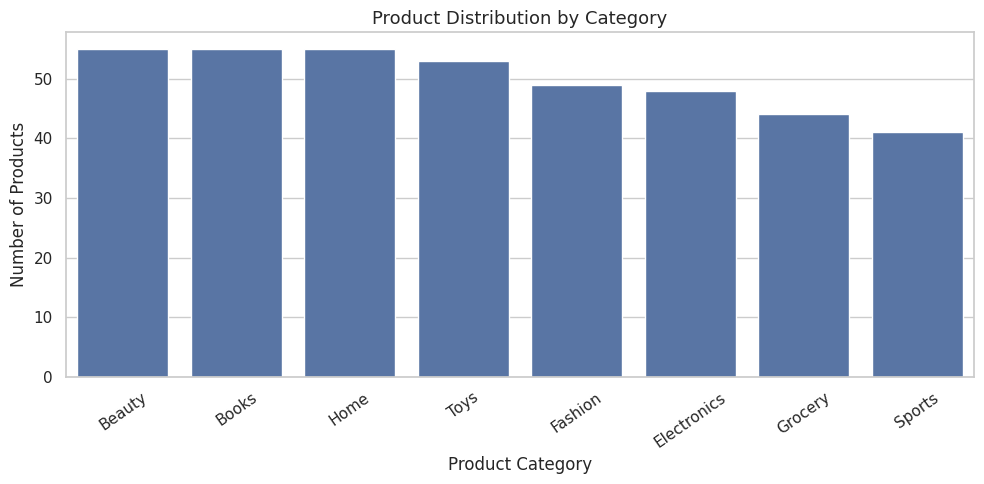


Category distribution:
category
Beauty         55
Books          55
Home           55
Toys           53
Fashion        49
Electronics    48
Grocery        44
Sports         41
Name: count, dtype: int64


In [19]:
# Product distribution by category

category_counts = items["category"].value_counts()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Product Distribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("\nCategory distribution:")
print(category_counts)

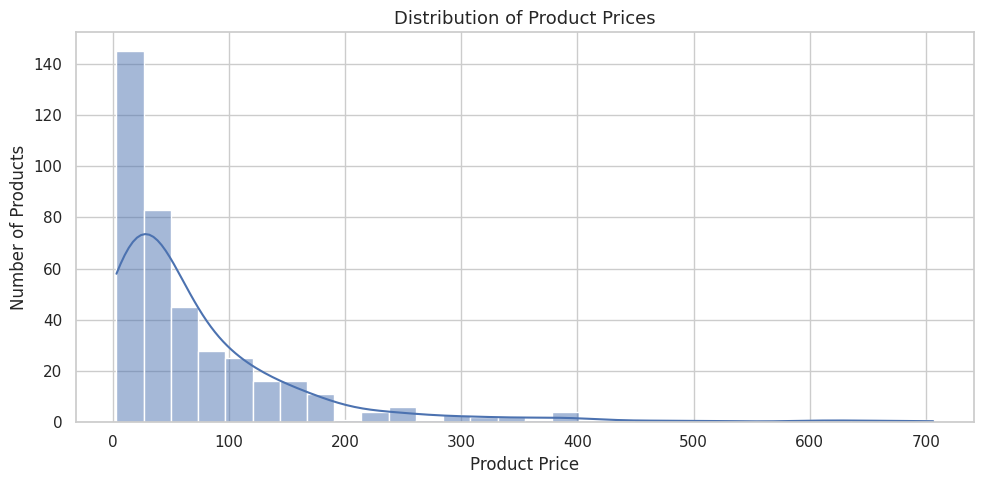


Price statistics:
count    400.000000
mean      76.291225
std      100.345658
min        3.150000
25%       18.475000
50%       38.805000
75%       94.432500
max      706.240000
Name: price, dtype: float64


In [20]:
# Product price distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=items,
    x="price",
    bins=30,
    kde=True
)

plt.title("Distribution of Product Prices")
plt.xlabel("Product Price")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

print("\nPrice statistics:")
print(items["price"].describe())

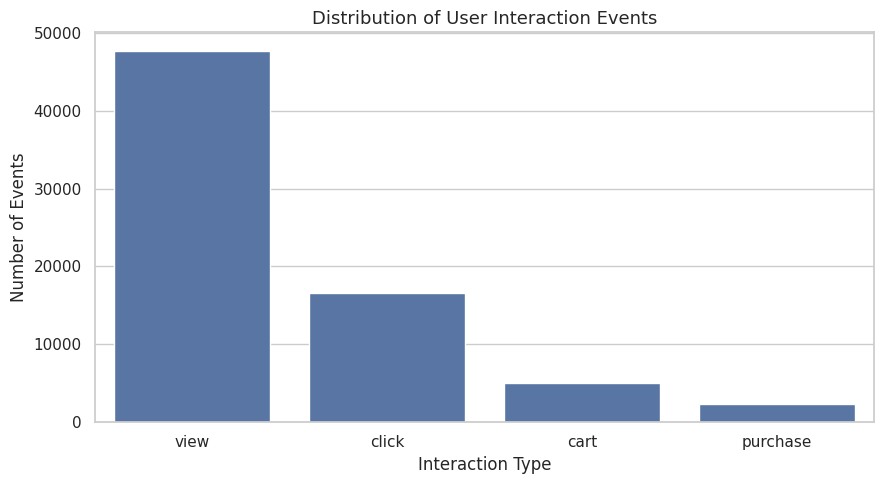


Interaction counts:
event_type
view        47677
click       16542
cart         5087
purchase     2293
Name: count, dtype: int64

Interaction percentages:
event_type
view        66.59
click       23.10
cart         7.10
purchase     3.20
Name: count, dtype: float64


In [21]:
# Interaction event distribution

event_order = ["view", "click", "cart", "purchase"]

event_counts = (
    inter["event_type"]
    .value_counts()
    .reindex(event_order)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=event_counts.index,
    y=event_counts.values
)

plt.title("Distribution of User Interaction Events")
plt.xlabel("Interaction Type")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

print("\nInteraction counts:")
print(event_counts)

print("\nInteraction percentages:")
print((event_counts / event_counts.sum() * 100).round(2))

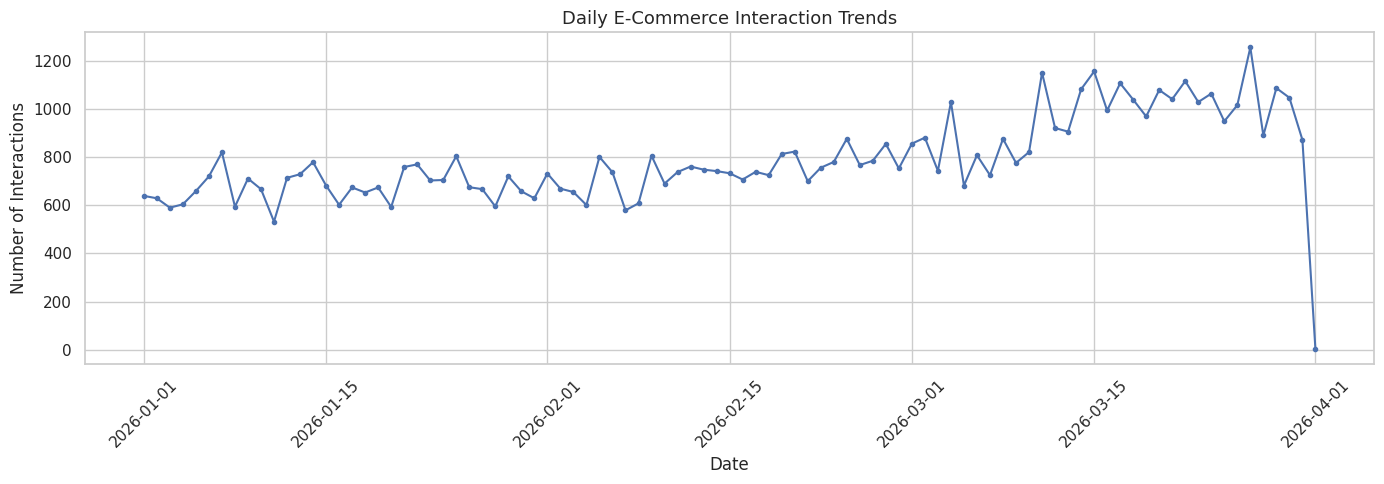

Average daily interactions: 786.8
Maximum daily interactions: 1256
Minimum daily interactions: 2


In [22]:
# Daily interaction trends

daily_interactions = (
    inter.groupby(inter["timestamp"].dt.date)
    .size()
)

plt.figure(figsize=(14, 5))

daily_interactions.plot(
    kind="line",
    marker="o",
    markersize=3
)

plt.title("Daily E-Commerce Interaction Trends")
plt.xlabel("Date")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average daily interactions:", round(daily_interactions.mean(), 2))
print("Maximum daily interactions:", daily_interactions.max())
print("Minimum daily interactions:", daily_interactions.min())

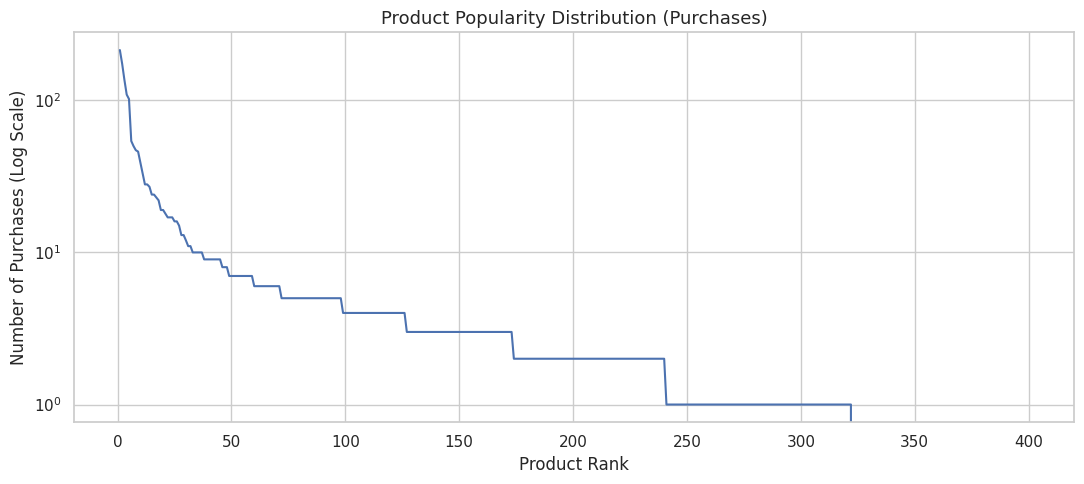

Products with at least one purchase: 322
Products with zero purchases: 78
Most purchased products:
item_id
82     214
259    174
73     136
202    109
301    102
328     54
65      50
131     47
117     46
84      39
Name: count, dtype: int64


In [23]:
# Product popularity based on purchases

purchase_counts = (
    inter[inter["event_type"] == "purchase"]
    ["item_id"]
    .value_counts()
)

# Include products with zero purchases
purchase_counts = purchase_counts.reindex(
    items["item_id"],
    fill_value=0
)

sorted_popularity = purchase_counts.sort_values(
    ascending=False
).reset_index(drop=True)

plt.figure(figsize=(11, 5))

plt.plot(
    range(1, len(sorted_popularity) + 1),
    sorted_popularity.values
)

plt.yscale("log")

plt.title("Product Popularity Distribution (Purchases)")
plt.xlabel("Product Rank")
plt.ylabel("Number of Purchases (Log Scale)")
plt.tight_layout()
plt.show()

print("Products with at least one purchase:",
      (purchase_counts > 0).sum())

print("Products with zero purchases:",
      (purchase_counts == 0).sum())

print("Most purchased products:")
print(purchase_counts.sort_values(ascending=False).head(10))

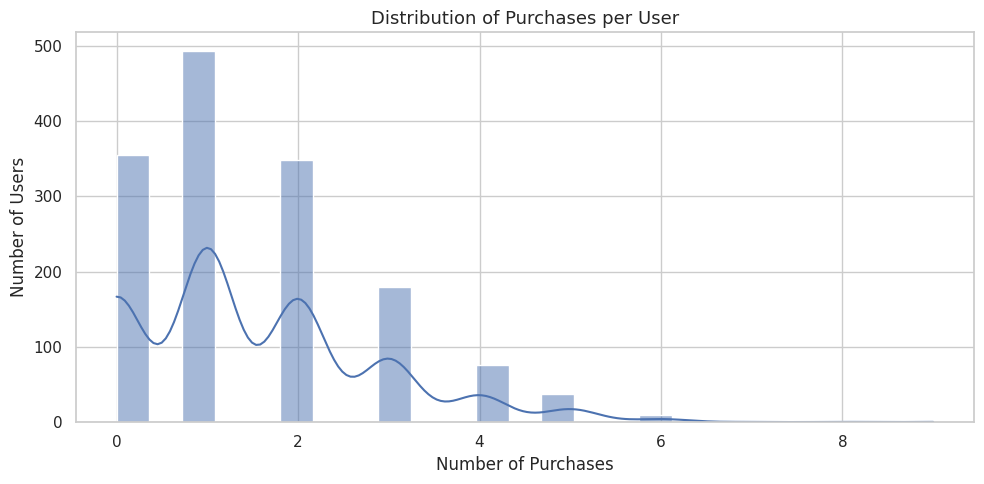

User purchase statistics:
count    1500.000000
mean        1.528667
std         1.329545
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         9.000000
dtype: float64

Users with zero purchases: 355


In [24]:
# Purchases per user

purchases_per_user = (
    inter[inter["event_type"] == "purchase"]
    .groupby("user_id")
    .size()
)

# Include users with zero purchases
purchases_per_user = purchases_per_user.reindex(
    users["user_id"],
    fill_value=0
)

plt.figure(figsize=(10, 5))

sns.histplot(
    purchases_per_user,
    bins=25,
    kde=True
)

plt.title("Distribution of Purchases per User")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

print("User purchase statistics:")
print(purchases_per_user.describe())

print("\nUsers with zero purchases:",
      (purchases_per_user == 0).sum())

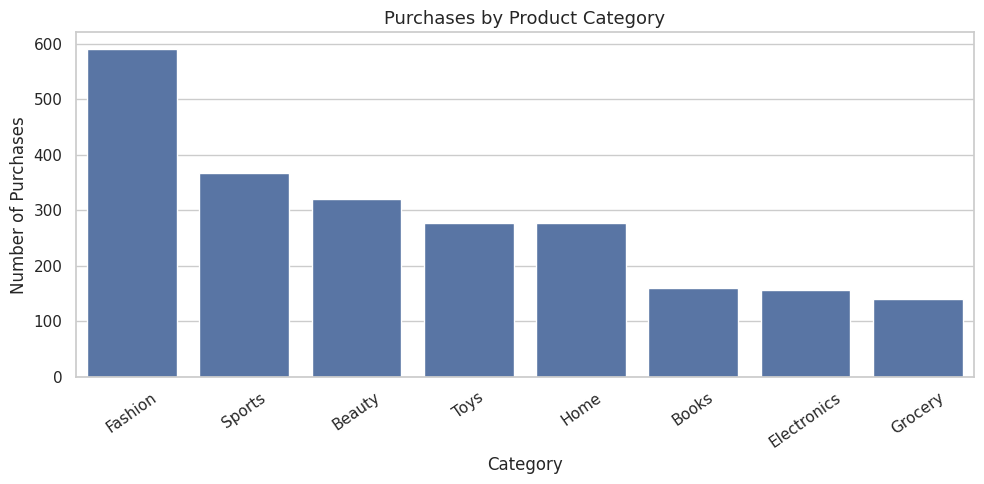

category
Fashion        591
Sports         367
Beauty         321
Toys           278
Home           277
Books          161
Electronics    157
Grocery        141
Name: count, dtype: int64


In [25]:
# Purchase distribution by category

purchase_data = inter[
    inter["event_type"] == "purchase"
].merge(
    items[["item_id", "category"]],
    on="item_id",
    how="left"
)

category_purchases = (
    purchase_data["category"]
    .value_counts()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_purchases.index,
    y=category_purchases.values
)

plt.title("Purchases by Product Category")
plt.xlabel("Category")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print(category_purchases)

In [26]:
# Purchase interaction matrix sparsity

unique_user_item_pairs = (
    inter[inter["event_type"] == "purchase"]
    [["user_id", "item_id"]]
    .drop_duplicates()
)

total_possible_pairs = len(users) * len(items)

observed_pairs = len(unique_user_item_pairs)

density = (
    observed_pairs / total_possible_pairs
) * 100

sparsity = 100 - density

print("Total possible user-item pairs:", total_possible_pairs)
print("Observed purchased user-item pairs:", observed_pairs)

print(f"Interaction matrix density: {density:.4f}%")
print(f"Interaction matrix sparsity: {sparsity:.4f}%")

Total possible user-item pairs: 600000
Observed purchased user-item pairs: 2195
Interaction matrix density: 0.3658%
Interaction matrix sparsity: 99.6342%


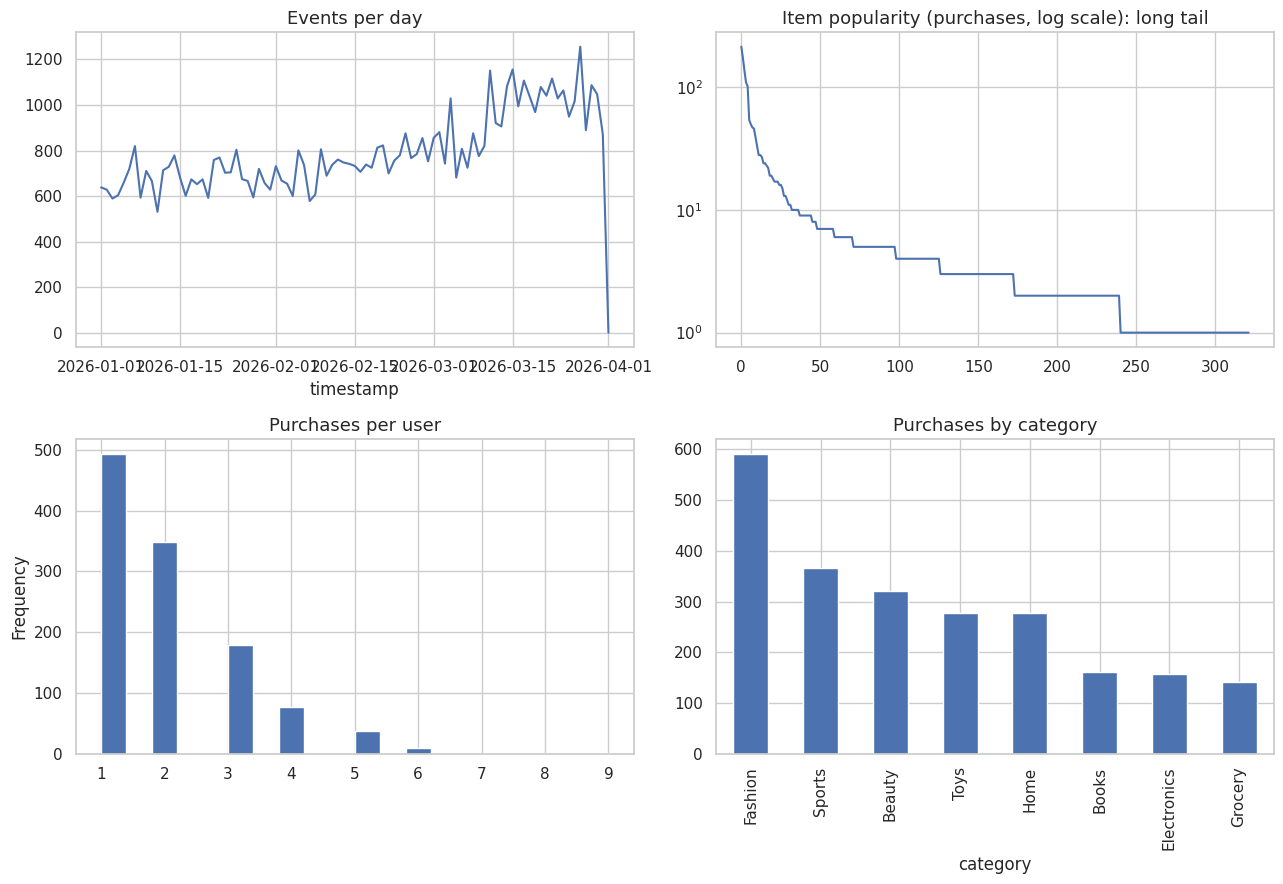

purchase-matrix density: 0.366%
top-10 items share of purchases: 0.42
median events per user: 46.0
funnel (events): {'view': 47677, 'click': 16542, 'cart': 5087, 'purchase': 2293}


In [27]:
# Combined figure and headline numbers for the report
buys_eda = inter[inter.event_type == "purchase"]
pop_counts = buys_eda.item_id.value_counts()

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

inter.groupby(inter.timestamp.dt.date).size().plot(ax=ax[0, 0], title="Events per day")

ax[0, 1].plot(range(len(pop_counts)), pop_counts.values)
ax[0, 1].set_yscale("log")
ax[0, 1].set_title("Item popularity (purchases, log scale): long tail")

buys_eda.groupby("user_id").size().plot.hist(bins=20, ax=ax[1, 0], title="Purchases per user")

buys_eda.merge(items, on="item_id").category.value_counts().plot.bar(ax=ax[1, 1], title="Purchases by category")

plt.tight_layout()
plt.savefig(REPORT_DIR / "eda.png", dpi=120)
plt.show()

pairs = buys_eda[["user_id", "item_id"]].drop_duplicates().shape[0]
print("purchase-matrix density: %.3f%%" % (100 * pairs / (len(users) * len(items))))
print("top-10 items share of purchases: %.2f" % (pop_counts.head(10).sum() / len(buys_eda)))
print("median events per user:", inter.groupby("user_id").size().median())
print("funnel (events):", inter.event_type.value_counts().to_dict())

## 6. Chronological split, leakage checks and cold-start analysis

Recommenders are used on the future, so we train on the past and evaluate on later days. A random split would let the model see events from after the ones it predicts.

- Train / validation history: events before **2026-03-04**
- Validation targets: purchases from 03-04 to 03-17 (used for tuning)
- Test targets: purchases from **2026-03-18** to the end of the data, about 14 days (used once, at the end)
- At test time the model may use everything before 03-18, which includes the validation period

In [28]:
from split import temporal_split, history_before

TRAIN_END = pd.Timestamp(VAL_START)
VAL_END = pd.Timestamp(TEST_START)

train_df, val_targets, test_targets = temporal_split(inter)

val_history = train_df                                   # known when making validation recommendations
test_history = history_before(inter, TEST_START)         # known when making final test recommendations

ts = inter["timestamp"]
print("Training events:", len(train_df))
print("Validation-period events:", int(((ts >= TRAIN_END) & (ts < VAL_END)).sum()))
print("Validation purchase targets:", len(val_targets))
print("Test-period events:", int((ts >= VAL_END).sum()))
print("Test purchase targets:", len(test_targets))
print("Test history:", len(test_history))

Training events: 44109
Validation-period events: 13034
Validation purchase targets: 436
Test-period events: 14456
Test purchase targets: 498
Test history: 57143


In [29]:
assert len(val_targets) > 0 and len(test_targets) > 0
assert train_df.timestamp.max() < TRAIN_END
assert val_targets.timestamp.min() >= TRAIN_END and val_targets.timestamp.max() < VAL_END
assert test_targets.timestamp.min() >= VAL_END
assert val_history.timestamp.max() < TRAIN_END
assert test_history.timestamp.max() < VAL_END
assert train_df.timestamp.max() < val_targets.timestamp.min()
assert test_history.timestamp.max() < test_targets.timestamp.min()
assert set(val_targets.event_type.unique()) == {"purchase"}
assert set(test_targets.event_type.unique()) == {"purchase"}

late_items = items[items.launch_date >= TRAIN_END].item_id
assert not train_df.item_id.isin(late_items).any(), "future items in train"
print("All temporal leakage checks passed!")

All temporal leakage checks passed!


In [30]:
for name, hist, tgt in [("VAL", val_history, val_targets), ("TEST", test_history, test_targets)]:
    cold_users = set(tgt.user_id) - set(hist.user_id)
    cold_items = set(tgt.item_id) - set(hist.item_id)
    print(f"[{name}] target users with NO history: {len(cold_users)} of {tgt.user_id.nunique()}")
    print(f"[{name}] target purchases on items with NO history: {100*tgt.item_id.isin(cold_items).mean():.1f}%")
    prev = hist[hist.event_type == "purchase"][["user_id", "item_id"]].drop_duplicates().assign(seen=1)
    rep = tgt.merge(prev, how="left", on=["user_id", "item_id"]).seen.notna().mean()
    print(f"[{name}] purchases repeating an earlier purchase: {100*rep:.1f}%\n")

[VAL] target users with NO history: 39 of 354
[VAL] target purchases on items with NO history: 3.0%
[VAL] purchases repeating an earlier purchase: 6.0%

[TEST] target users with NO history: 15 of 362
[TEST] target purchases on items with NO history: 0.8%
[TEST] purchases repeating an earlier purchase: 4.8%



### Cold-Start and Repeat-Purchase Analysis

Cold-start behaviour was evaluated using historical interactions available at each evaluation cutoff.

During validation, 39 of 354 target users (11.0%) had no prior interaction history. This decreased to 15 of 362 users (4.1%) during testing.

Purchases involving items with no prior interaction history accounted for 3.0% of validation purchases and 0.8% of test purchases.

Repeat purchases of previously purchased user-item pairs represented 6.0% of validation purchases and 4.8% of test purchases.

These findings indicate that a personalized recommendation approach should be complemented by a popularity-based fallback for users without interaction history. The relatively small proportion of purchases involving unseen items also suggests that historical interaction-based recommendations can cover much of the observed demand, although new-item handling remains important.

Because repeat purchases are rare (about 5%), previously purchased products are excluded from recommendations, and repeat pairs are removed from the evaluation ground truth so that models are not penalized for items they deliberately never recommend.

## 7. Popularity baseline (validation)

The baseline every other model has to beat. The guard cell first proves that a model refuses history from after its cutoff.

In [31]:
import metrics, models
importlib.reload(metrics); importlib.reload(models)
from metrics import evaluate
from models import PopularityRecommender, ItemCFRecommender, ContentBasedRecommender, HybridRecommender

In [32]:
# the guard must fire when we deliberately leak
try:
    PopularityRecommender().fit(inter, items, TRAIN_END)   # full data, includes the future
    print("BAD: leakage not caught")
except ValueError as e:
    print("guard works:", e)

guard works: history contains events at/after cutoff 2026-03-04 00:00:00: leakage


In [33]:
pop = PopularityRecommender().fit(train_df, items, TRAIN_END)
catalog = len(pop.ranking)

for k in (5, 10, 20):
    print(k, evaluate(pop.recommend, train_df, val_targets, k=k, catalog_size=catalog))

# cold-start users only (no history before the cutoff)
cold = set(val_targets.user_id) - set(train_df.user_id)
print("cold users:", evaluate(pop.recommend, train_df, val_targets, k=10,
                              catalog_size=catalog, user_subset=cold))

5 {'n_users': 340, 'P@5': np.float64(0.08), 'R@5': np.float64(0.33578431372549017), 'NDCG@5': np.float64(0.22263956700723572), 'coverage': 0.018469656992084433}
10 {'n_users': 340, 'P@10': np.float64(0.04970588235294117), 'R@10': np.float64(0.4161764705882353), 'NDCG@10': np.float64(0.24905273443103448), 'coverage': 0.03430079155672823}
20 {'n_users': 340, 'P@20': np.float64(0.029558823529411766), 'R@20': np.float64(0.49166666666666664), 'NDCG@20': np.float64(0.2688464630079352), 'coverage': 0.06068601583113457}
cold users: {'n_users': 39, 'P@10': np.float64(0.06410256410256411), 'R@10': np.float64(0.5341880341880342), 'NDCG@10': np.float64(0.34869654787390375), 'coverage': 0.026385224274406333}


## 8. Personalized models (validation)

- **Item-CF:** scores an item by its similarity to the items in the user's weighted history.
- **Content-based:** builds a taste profile from category, brand and price band of past items. Price bands and vocabulary are learned from live items only.
- Both exclude already-bought and not-yet-launched items, and fall back to popularity for users with no history.

In [34]:
importlib.reload(models)
from models import PopularityRecommender, ItemCFRecommender, ContentBasedRecommender

catalog = int((items.launch_date <= TRAIN_END).sum())
cold = set(val_targets.user_id) - set(train_df.user_id)

cand = {
    "popularity": PopularityRecommender().fit(train_df, items, TRAIN_END),
    "item_cf":    ItemCFRecommender().fit(train_df, items, TRAIN_END),
    "content":    ContentBasedRecommender().fit(train_df, items, TRAIN_END),
}

rows = []
for name, m in cand.items():
    r = evaluate(m.recommend, train_df, val_targets, k=10, catalog_size=catalog)
    c = evaluate(m.recommend, train_df, val_targets, k=10, catalog_size=catalog, user_subset=cold)
    rows.append({"model": name, "R@10": r["R@10"], "P@10": r["P@10"], "NDCG@10": r["NDCG@10"],
                 "coverage": r["coverage"], "cold R@10": c["R@10"]})
pd.DataFrame(rows).round(3)

,model,R@10,P@10,NDCG@10,coverage,cold R@10
0,popularity,0.416,0.050,0.249,0.034,0.534
1,item_cf,0.497,0.059,0.301,0.303,0.534
2,content,0.278,0.034,0.168,0.910,0.534


## 9. Hybrid tuning (validation only)

Blend of per-user normalized item-CF, content and popularity scores. Weights are chosen on validation from a 24-configuration grid. The bootstrap CIs here are exploratory, because the configuration was selected on the same users. The independent check is the test set in Part 10.

In [35]:
importlib.reload(models)
from models import HybridRecommender

cf, cb = cand["item_cf"], cand["content"]
res = []
for w_cb in (0, 0.1, 0.25, 0.5):
    for w_pop in (0, 0.1, 0.25, 0.5):
        h = HybridRecommender(cf, cb, w_cb, w_pop)
        r = evaluate(h.recommend, train_df, val_targets, k=10, catalog_size=catalog)
        res.append({"w_cb": w_cb, "w_pop": w_pop, "R@10": r["R@10"],
                    "NDCG@10": r["NDCG@10"], "coverage": r["coverage"]})
grid = pd.DataFrame(res).sort_values("NDCG@10", ascending=False)
print(grid.round(3).to_string(index=False))

 w_cb  w_pop  R@10  NDCG@10  coverage
 0.50   0.50 0.508    0.332     0.298
 0.25   0.50 0.503    0.325     0.230
 0.50   0.25 0.504    0.322     0.375
 0.10   0.50 0.497    0.319     0.195
 0.25   0.25 0.504    0.315     0.296
 0.10   0.25 0.493    0.309     0.261
 0.50   0.10 0.483    0.309     0.409
 0.00   0.50 0.485    0.308     0.182
 0.10   0.10 0.495    0.305     0.293
 0.00   0.10 0.494    0.305     0.280
 0.00   0.25 0.497    0.305     0.230
 0.10   0.00 0.499    0.304     0.335
 0.25   0.10 0.492    0.302     0.340
 0.00   0.00 0.497    0.301     0.303
 0.25   0.00 0.491    0.300     0.354
 0.50   0.00 0.479    0.298     0.433


In [36]:
from metrics import ndcg_at_k

def per_user_ndcg(fn, history, targets, k=10):
    seen = (history[history.event_type == "purchase"]
            .groupby("user_id")["item_id"].apply(set).to_dict())
    truth = (targets[targets.event_type == "purchase"]
             .groupby("user_id")["item_id"].apply(set).to_dict())
    out = {}
    for user_id, relevant in truth.items():
        relevant = relevant - seen.get(user_id, set())
        if relevant:
            out[user_id] = ndcg_at_k(fn(user_id, k), relevant, k)
    return pd.Series(out)

def boot_diff(a, b, n=2000):
    common = a.index.intersection(b.index)          # explicit user alignment
    d = (a.loc[common] - b.loc[common]).values
    rng = np.random.default_rng(SEED)
    means = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), np.percentile(means, [2.5, 97.5]), len(common)

# 1) extended grid beyond the old edge
res = []
for w_cb in (0.5, 1, 2):
    for w_pop in (0.5, 1, 2):
        h = HybridRecommender(cf, cb, w_cb, w_pop)
        r = evaluate(h.recommend, train_df, val_targets, k=10, catalog_size=catalog)
        res.append({"w_cb": w_cb, "w_pop": w_pop, "R@10": r["R@10"],
                    "NDCG@10": r["NDCG@10"], "coverage": r["coverage"]})
grid2 = pd.DataFrame(res)

# 2) select across ALL unique configs (original grid + extension)
all_grid = (pd.concat([grid, grid2])
            .drop_duplicates(["w_cb", "w_pop"])
            .sort_values("NDCG@10", ascending=False))
print(f"{len(all_grid)} unique configs tested; top 8:")
print(all_grid.head(8).round(3).to_string(index=False))

# 3) paired bootstrap: best config vs item-CF
best = all_grid.iloc[0]
print("\nbest config: w_cb =", best.w_cb, " w_pop =", best.w_pop)
hb = HybridRecommender(cf, cb, best.w_cb, best.w_pop)
a = per_user_ndcg(hb.recommend, train_df, val_targets)
b = per_user_ndcg(cf.recommend, train_df, val_targets)
mean_d, ci, n = boot_diff(a, b)
print(f"NDCG@10 gain over item_cf: {mean_d:.3f}  95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  (n={n})")

24 unique configs tested; top 8:
 w_cb  w_pop  R@10  NDCG@10  coverage
 2.00   2.00 0.496    0.333     0.369
 0.50   0.50 0.508    0.332     0.298
 1.00   1.00 0.509    0.331     0.317
 1.00   2.00 0.487    0.326     0.177
 0.50   1.00 0.495    0.326     0.198
 0.25   0.50 0.503    0.325     0.230
 0.50   0.25 0.504    0.322     0.375
 1.00   0.50 0.477    0.322     0.449

best config: w_cb = 2.0  w_pop = 2.0
NDCG@10 gain over item_cf: 0.032  95% CI [0.012, 0.052]  (n=340)


In [37]:
FINAL_W_CB, FINAL_W_POP = 1.0, 1.0

hf = HybridRecommender(cf, cb, FINAL_W_CB, FINAL_W_POP)
a = per_user_ndcg(hf.recommend, train_df, val_targets)
b = per_user_ndcg(cf.recommend, train_df, val_targets)
c = per_user_ndcg(cand["popularity"].recommend, train_df, val_targets)

for name, base in [("item_cf", b), ("popularity", c)]:
    d, ci, n = boot_diff(a, base)
    print(f"hybrid(1,1) NDCG@10 gain over {name}: {d:.3f}  95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  (n={n})")

r = evaluate(hf.recommend, train_df, val_targets, k=10, catalog_size=catalog)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})

hybrid(1,1) NDCG@10 gain over item_cf: 0.030  95% CI [0.014, 0.048]  (n=340)
hybrid(1,1) NDCG@10 gain over popularity: 0.082  95% CI [0.057, 0.108]  (n=340)
{'n_users': 340, 'P@10': np.float64(0.06), 'R@10': np.float64(0.509), 'NDCG@10': np.float64(0.331), 'coverage': 0.317}


## 10. Final test evaluation (run once)

Models are refit on all history before 2026-03-18 and scored once on the test targets. Nothing is tuned after this cell.

In [38]:
importlib.reload(models)
from models import PopularityRecommender, ItemCFRecommender, ContentBasedRecommender, HybridRecommender

# --- refit on all history known at the test cutoff (nothing is tuned here) ---
catalog_t = int((items.launch_date <= VAL_END).sum())
pop_t = PopularityRecommender().fit(test_history, items, VAL_END)
cf_t  = ItemCFRecommender().fit(test_history, items, VAL_END)
cb_t  = ContentBasedRecommender().fit(test_history, items, VAL_END)
hy_t  = HybridRecommender(cf_t, cb_t, FINAL_W_CB, FINAL_W_POP)
final = {"popularity": pop_t, "item_cf": cf_t, "content": cb_t, "hybrid": hy_t}

# --- headline table at K = 5, 10, 20 ---
rows = []
for name, m in final.items():
    for k in (5, 10, 20):
        r = evaluate(m.recommend, test_history, test_targets, k=k, catalog_size=catalog_t)
        rows.append({"model": name, "K": k, "n_users": r["n_users"], "P": r[f"P@{k}"],
                     "R": r[f"R@{k}"], "NDCG": r[f"NDCG@{k}"], "coverage": r["coverage"]})
test_table = pd.DataFrame(rows)
print(test_table.round(3).to_string(index=False))

# --- paired bootstrap CIs on NDCG@10 ---
a = per_user_ndcg(hy_t.recommend, test_history, test_targets)
for name, base_m in [("item_cf", cf_t), ("popularity", pop_t)]:
    b = per_user_ndcg(base_m.recommend, test_history, test_targets)
    d, ci, n = boot_diff(a, b)
    print(f"\nhybrid vs {name}: NDCG@10 gain {d:.3f}  95% CI [{ci[0]:.3f}, {ci[1]:.3f}]  (n={n})")

# --- cold vs warm users at K = 10 ---
cold_t = set(test_targets.user_id) - set(test_history.user_id)
warm_t = set(test_targets.user_id) - cold_t
for label, subset in [("cold", cold_t), ("warm", warm_t)]:
    print(f"\n{label} users:")
    for name, m in final.items():
        r = evaluate(m.recommend, test_history, test_targets, k=10,
                     catalog_size=catalog_t, user_subset=subset)
        print(f"  {name:10s} n={r['n_users']:3d}  R@10={r['R@10']:.3f}  NDCG@10={r['NDCG@10']:.3f}")

test_table.to_csv(OUTPUT_DIR / "test_results.csv", index=False)

     model  K  n_users     P     R  NDCG  coverage
popularity  5      345 0.075 0.282 0.200     0.018
popularity 10      345 0.049 0.362 0.229     0.033
popularity 20      345 0.031 0.466 0.257     0.061
   item_cf  5      345 0.090 0.338 0.241     0.152
   item_cf 10      345 0.062 0.472 0.286     0.276
   item_cf 20      345 0.039 0.590 0.318     0.494
   content  5      345 0.042 0.154 0.124     0.747
   content 10      345 0.032 0.238 0.152     0.909
   content 20      345 0.024 0.360 0.185     0.972
    hybrid  5      345 0.098 0.370 0.268     0.144
    hybrid 10      345 0.063 0.482 0.307     0.314
    hybrid 20      345 0.038 0.573 0.332     0.592

hybrid vs item_cf: NDCG@10 gain 0.021  95% CI [0.006, 0.037]  (n=345)

hybrid vs popularity: NDCG@10 gain 0.078  95% CI [0.050, 0.107]  (n=345)

cold users:
  popularity n= 15  R@10=0.311  NDCG@10=0.238
  item_cf    n= 15  R@10=0.311  NDCG@10=0.238
  content    n= 15  R@10=0.311  NDCG@10=0.238
  hybrid     n= 15  R@10=0.311  NDCG@10=0

## 11. Error analysis and explanations

Where does the hybrid hit and miss: by item popularity tier, user history size, category and items with no history. Then explanations for individual recommendations. `score_share` is each signal's share of the normalized, weighted blend, not a causal attribution.

In [39]:
k = 10
truth = test_targets.groupby("user_id").item_id.apply(set).to_dict()
seen = test_history[test_history.event_type == "purchase"].groupby("user_id").item_id.apply(set).to_dict()
hist_buys = test_history[test_history.event_type == "purchase"].item_id.value_counts()
hist_items = set(test_history.item_id)
n_hist_buys = test_history[test_history.event_type == "purchase"].groupby("user_id").size()

# popularity tier by purchase-count rank among all items: head = top 10%, mid = next 40%, tail = rest
rank = hist_buys.reindex(items.item_id).fillna(0).rank(ascending=False, method="first")
tier = pd.cut(rank.values, [0, 0.1 * len(items), 0.5 * len(items), len(items)],
              labels=["head", "mid", "tail"])
tier = pd.Series(tier, index=items.item_id.values)

rows = []
for u, rel in truth.items():
    rel = rel - seen.get(u, set())
    if not rel:
        continue
    recs = set(hy_t.recommend(u, k))
    for i in rel:
        rows.append({"user_id": u, "item_id": i, "hit": i in recs})
tl = pd.DataFrame(rows)
tl["tier"] = tl.item_id.map(tier)
tl["no_history_item"] = ~tl.item_id.isin(hist_items)
tl["category"] = tl.item_id.map(items.set_index("item_id").category)
tl["user_buys"] = tl.user_id.map(n_hist_buys).fillna(0)
tl["user_bucket"] = pd.cut(tl.user_buys, [-1, 0, 2, 4, np.inf], labels=["0", "1-2", "3-4", "5+"])

print("overall target hit rate @10: %.3f  (targets=%d)" % (tl.hit.mean(), len(tl)))
print("\nby item popularity tier:\n", tl.groupby("tier", observed=True).hit.agg(["mean", "count"]).round(3))
print("\nitems with NO history:\n", tl.groupby("no_history_item").hit.agg(["mean", "count"]).round(3))
print("\nby user history size (purchases):\n", tl.groupby("user_bucket", observed=True).hit.agg(["mean", "count"]).round(3))
print("\nby category:\n", tl.groupby("category").hit.agg(["mean", "count"]).round(3))

overall target hit rate @10: 0.469  (targets=467)

by item popularity tier:
        mean  count
tier              
head  0.752    274
mid   0.110    109
tail  0.012     84

items with NO history:
                   mean  count
no_history_item              
False            0.473    463
True             0.000      4

by user history size (purchases):
               mean  count
user_bucket              
0            0.498    207
1-2          0.445    211
3-4          0.432     44
5+           0.600      5

by category:
               mean  count
category                 
Beauty       0.392     74
Books        0.243     37
Electronics  0.172     29
Fashion      0.768     99
Grocery      0.308     39
Home         0.200     50
Sports       0.595     79
Toys         0.517     60


In [40]:
import explain; importlib.reload(explain)
from explain import explain as explain_rec

# demo: a warm test user
u = next(u for u in truth if u in hy_t.cf.uidx)
for i in hy_t.recommend(u, 3):
    print(explain_rec(hy_t, items, u, i), "\n")

# one MISS to analyze for the report
miss = tl[(~tl.hit) & (tl.user_id == u)]
print("user", u, "missed targets:\n", miss)

{'item_id': 82, 'title': 'Smart Fashion Item 82', 'category': 'Fashion', 'price': 108.84, 'score_share': {'item_cf': 0.36, 'content': 0.28, 'popularity': 0.36}, 'item_cf_driven_by': [{'title': 'Comfort Fashion Item 73', 'influence': 1.989}, {'title': 'Pro Beauty Item 202', 'influence': 0.524}, {'title': 'Comfort Sports Item 259', 'influence': 0.394}], 'category_share_of_your_activity': 0.35, 'popularity_rank': 1} 

{'item_id': 73, 'title': 'Comfort Fashion Item 73', 'category': 'Fashion', 'price': 60.0, 'score_share': {'item_cf': 0.31, 'content': 0.32, 'popularity': 0.36}, 'item_cf_driven_by': [{'title': 'Smart Fashion Item 82', 'influence': 1.248}, {'title': 'Pro Beauty Item 202', 'influence': 0.401}, {'title': 'Comfort Fashion Item 167', 'influence': 0.338}], 'category_share_of_your_activity': 0.35, 'popularity_rank': 3} 

{'item_id': 117, 'title': 'Mini Fashion Item 117', 'category': 'Fashion', 'price': 74.73, 'score_share': {'item_cf': 0.37, 'content': 0.33, 'popularity': 0.3}, 'it

In [41]:
# Is the category gap really a popularity-tier gap?
print("share of each category's targets by tier:")
print(pd.crosstab(tl.category, tl.tier, normalize="index").round(2))
print("\nhit rate by tier within category (small counts are noisy):")
print(tl.groupby(["category", "tier"], observed=True).hit.agg(["mean", "count"]).round(2).to_string())

# One real error: the first missed non-head target
misses = tl[(~tl.hit) & (tl.tier != "head")]

if len(misses) == 0:
    print("No missed mid/tail targets found.")
else:
    m = misses.iloc[0]
    u, i = int(m.user_id), int(m.item_id)
    full = hy_t.recommend(u, 400)                         # full ranked candidate list
    rank = full.index(i) + 1 if i in full else None
    meta = items.set_index("item_id")

    hist_u = test_history[test_history.user_id == u]
    print(f"\nUSER {u}: missed item {i} ({meta.loc[i, 'title']}, tier={m.tier}, price={meta.loc[i, 'price']})")
    print("it was ranked:", rank, "of", len(full), "candidates")
    print("user's history by category (all event types):")
    print(hist_u.merge(items, on="item_id").category.value_counts().to_string())
    print("\ntop-5 recommended:")
    for r in hy_t.recommend(u, 5):
        print("  ", meta.loc[r, "title"], "| price", meta.loc[r, "price"])
    print("\nexplanation of the missed item:")
    print(explain_rec(hy_t, items, u, i))

share of each category's targets by tier:
tier         head   mid  tail
category                     
Beauty       0.51  0.30  0.19
Books        0.30  0.35  0.35
Electronics  0.28  0.34  0.38
Fashion      0.87  0.05  0.08
Grocery      0.74  0.10  0.15
Home         0.34  0.42  0.24
Sports       0.58  0.25  0.16
Toys         0.65  0.23  0.12

hit rate by tier within category (small counts are noisy):
                  mean  count
category    tier             
Beauty      head  0.71     38
            mid   0.09     22
            tail  0.00     14
Books       head  0.73     11
            mid   0.08     13
            tail  0.00     13
Electronics head  0.38      8
            mid   0.10     10
            tail  0.09     11
Fashion     head  0.88     86
            mid   0.00      5
            tail  0.00      8
Grocery     head  0.41     29
            mid   0.00      4
            tail  0.00      6
Home        head  0.59     17
            mid   0.00     21
            tail  0.00     1

## 12. Training pipeline and saved artifact

`src/train.py` reloads the CSVs, rebuilds the split, fits the models, evaluates on the test targets and saves `models/recommender.joblib` and `outputs/metrics.json`. The numbers should match Part 10.

In [42]:
%cd /content/drive/MyDrive/ecommerce_recommendation_engine
!python src/train.py

/content/drive/MyDrive/ecommerce_recommendation_engine
popularity {'n_users': 345.0, 'P@10': 0.049, 'R@10': 0.362, 'NDCG@10': 0.229, 'coverage': 0.033}
item_cf {'n_users': 345.0, 'P@10': 0.062, 'R@10': 0.472, 'NDCG@10': 0.286, 'coverage': 0.276}
content {'n_users': 345.0, 'P@10': 0.032, 'R@10': 0.238, 'NDCG@10': 0.152, 'coverage': 0.909}
hybrid {'n_users': 345.0, 'P@10': 0.063, 'R@10': 0.482, 'NDCG@10': 0.307, 'coverage': 0.314}
saved: /content/drive/MyDrive/ecommerce_recommendation_engine/models/recommender.joblib


## 13. Inference API demo

Starts the FastAPI service in the background and calls it. The responses come from the saved model artifact.

In [43]:
!pip install -q fastapi uvicorn requests

import subprocess, time, requests, json
PROJECT = "/content/drive/MyDrive/ecommerce_recommendation_engine"
server = subprocess.Popen(["python", "-m", "uvicorn", "api:app", "--app-dir", "src", "--port", "8000"],
                          cwd=PROJECT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
time.sleep(8)

print(requests.get("http://127.0.0.1:8000/health").json())

r = requests.get("http://127.0.0.1:8000/recommend/5", params={"k": 3}).json()
print(json.dumps(r, indent=2)[:1800])

{'status': 'ok', 'model_as_of': '2026-03-18 00:00:00', 'weights': {'w_cb': 1.0, 'w_pop': 1.0}}
{
  "user_id": 5,
  "strategy": "hybrid",
  "known_user": true,
  "model_as_of": "2026-03-18 00:00:00",
  "recommendations": [
    {
      "rank": 1,
      "item_id": 82,
      "title": "Smart Fashion Item 82",
      "category": "Fashion",
      "price": 108.84,
      "explanation": {
        "item_id": 82,
        "title": "Smart Fashion Item 82",
        "category": "Fashion",
        "price": 108.84,
        "score_share": {
          "item_cf": 0.33,
          "content": 0.33,
          "popularity": 0.33
        },
        "item_cf_driven_by": [
          {
            "title": "Comfort Fashion Item 73",
            "influence": 1.989
          },
          {
            "title": "Ultra Fashion Item 328",
            "influence": 1.039
          },
          {
            "title": "Mini Fashion Item 117",
            "influence": 0.861
          }
        ],
        "category_share_of_yo

In [44]:
# 1) API output == what the notebook model produces (proves it loads the artifact, nothing hard-coded)
api_ids = [x["item_id"] for x in requests.get("http://127.0.0.1:8000/recommend/5", params={"k": 10}).json()["recommendations"]]
nb_ids = [int(i) for i in hy_t.recommend(5, 10)]
print("API matches notebook model:", api_ids == nb_ids)

# 2) unknown user -> popularity fallback, not an error
r = requests.get("http://127.0.0.1:8000/recommend/999999", params={"k": 3}).json()
print(r["strategy"], [x["title"] for x in r["recommendations"]])

# 3) bad input is rejected
print("k=0 ->", requests.get("http://127.0.0.1:8000/recommend/5", params={"k": 0}).status_code)

# server.terminate()   # run when you're done

API matches notebook model: True
popularity_fallback ['Smart Fashion Item 82', 'Comfort Sports Item 259', 'Comfort Fashion Item 73']
k=0 -> 422


## 14. Tests

Unit tests (metrics hand-computed example, split, leakage guards, recommendation rules, determinism) and API tests (needs the artifact from Part 12).

In [45]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/tests/conftest.py
import sys
from pathlib import Path
import pandas as pd
import pytest

sys.path.insert(0, str(Path(__file__).resolve().parent.parent / "src"))

CUTOFF = pd.Timestamp("2026-02-01")


@pytest.fixture
def items():
    return pd.DataFrame({
        "item_id": range(6),
        "category": ["A", "A", "B", "B", "A", "B"],
        "brand": ["x", "y", "x", "y", "x", "y"],
        "price": [10.0, 20.0, 30.0, 40.0, 15.0, 25.0],
        "title": [f"item {i}" for i in range(6)],
        # item 5 launches AFTER the cutoff: must never be recommended or leak into fitting
        "launch_date": pd.to_datetime(["2026-01-01"] * 4 + ["2026-01-10", "2026-03-01"]),
    })


@pytest.fixture
def history():
    rows = [  # user, item, event, timestamp
        (0, 0, "view", "2026-01-05"), (0, 0, "purchase", "2026-01-06"),
        (0, 1, "click", "2026-01-07"), (0, 1, "purchase", "2026-01-08"),
        (1, 0, "view", "2026-01-09"), (1, 0, "purchase", "2026-01-10"),
        (1, 2, "purchase", "2026-01-11"),
        (2, 1, "purchase", "2026-01-12"), (2, 2, "view", "2026-01-13"),
        (2, 2, "purchase", "2026-01-14"), (2, 3, "view", "2026-01-15"),
    ]
    df = pd.DataFrame(rows, columns=["user_id", "item_id", "event_type", "timestamp"])
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    return df

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/tests/conftest.py


In [46]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/tests/test_pipeline.py
import numpy as np
import pandas as pd
import pytest

from conftest import CUTOFF
from metrics import precision_at_k, recall_at_k, ndcg_at_k, evaluate
from models import (PopularityRecommender, ItemCFRecommender,
                    ContentBasedRecommender, HybridRecommender)
from split import temporal_split, history_before
from config import VAL_START, TEST_START


# ---------- metrics: hand-computed example ----------
def test_metrics_hand_computed():
    recs, relevant = [1, 2, 3], {2, 9}
    assert precision_at_k(recs, relevant, 3) == pytest.approx(1 / 3)
    assert recall_at_k(recs, relevant, 3) == pytest.approx(1 / 2)
    # hit at rank 2: dcg = 1/log2(3); ideal = 1 + 1/log2(3)
    expected = (1 / np.log2(3)) / (1 + 1 / np.log2(3))
    assert ndcg_at_k(recs, relevant, 3) == pytest.approx(expected)


def test_evaluate_excludes_already_bought_and_handles_empty(history):
    targets = history.iloc[0:0]                      # no targets at all
    out = evaluate(lambda u, k: [1, 2], history, targets, k=2)
    assert out["n_users"] == 0 and np.isnan(out["R@2"])


def test_evaluate_rejects_leaky_history(history):
    future = history.assign(timestamp=history.timestamp + pd.Timedelta(days=365))
    with pytest.raises(ValueError):
        evaluate(lambda u, k: [0], future, history[history.event_type == "purchase"], k=1)


# ---------- split: no overlap between history and targets ----------
def test_temporal_split_has_no_overlap():
    ts = pd.date_range("2026-01-01", "2026-04-01", freq="6h")
    inter = pd.DataFrame({"user_id": 0, "item_id": 0, "timestamp": ts,
                          "event_type": ["purchase", "view"] * (len(ts) // 2) + ["purchase"] * (len(ts) % 2)})
    train, val_t, test_t = temporal_split(inter)
    assert train.timestamp.max() < pd.Timestamp(VAL_START)
    assert val_t.timestamp.min() >= pd.Timestamp(VAL_START)
    assert val_t.timestamp.max() < pd.Timestamp(TEST_START)
    assert test_t.timestamp.min() >= pd.Timestamp(TEST_START)
    assert set(val_t.event_type) == set(test_t.event_type) == {"purchase"}
    assert history_before(inter, TEST_START).timestamp.max() < pd.Timestamp(TEST_START)


# ---------- models: leakage guards ----------
@pytest.mark.parametrize("cls", [PopularityRecommender, ItemCFRecommender, ContentBasedRecommender])
def test_models_refuse_history_after_cutoff(cls, items, history):
    with pytest.raises(ValueError):
        cls().fit(history, items, pd.Timestamp("2026-01-10"))   # history extends past this cutoff


# ---------- models: recommendation rules ----------
def build(items, history):
    cf = ItemCFRecommender().fit(history, items, CUTOFF)
    cb = ContentBasedRecommender().fit(history, items, CUTOFF)
    return PopularityRecommender().fit(history, items, CUTOFF), cf, cb, HybridRecommender(cf, cb, 1.0, 1.0)


def test_never_recommends_unlaunched_or_already_bought(items, history):
    bought = history[history.event_type == "purchase"].groupby("user_id").item_id.apply(set).to_dict()
    for model in build(items, history):
        for u in (0, 1, 2):
            recs = model.recommend(u, 5)
            assert 5 not in recs, "recommended an item that launches after the cutoff"
            assert not set(recs) & bought[u], "recommended something the user already bought"
            assert len(recs) == len(set(recs)), "duplicate items in a list"


def test_unknown_user_falls_back_to_popularity(items, history):
    pop, cf, cb, hybrid = build(items, history)
    assert cf.recommend(999, 3) == pop.recommend(999, 3)
    assert hybrid.recommend(999, 3) == pop.recommend(999, 3)


def test_training_is_deterministic(items, history):
    a = build(items, history)[3].recommend(0, 3)
    b = build(items, history)[3].recommend(0, 3)
    assert a == b


def test_future_item_metadata_does_not_change_features(items, history):
    """Changing a not-yet-launched item's price must not change the fitted content features for live items."""
    cb1 = ContentBasedRecommender().fit(history, items, CUTOFF)
    changed = items.copy()
    changed.loc[changed.item_id == 5, "price"] = 9999.0
    cb2 = ContentBasedRecommender().fit(history, changed, CUTOFF)
    assert (cb1.F[:5] != cb2.F[:5]).nnz == 0

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/tests/test_pipeline.py


In [47]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/tests/test_api.py
import pytest
from config import MODEL_DIR

pytest.importorskip("httpx")
if not (MODEL_DIR / "recommender.joblib").exists():
    pytest.skip("run src/train.py first to create the model artifact", allow_module_level=True)

from fastapi.testclient import TestClient
import api

client = TestClient(api.app)


def test_health():
    r = client.get("/health")
    assert r.status_code == 200 and r.json()["status"] == "ok"


def test_recommend_returns_k_ranked_items_with_explanations():
    body = client.get("/recommend/5", params={"k": 5}).json()
    assert body["strategy"] == "hybrid" and len(body["recommendations"]) == 5
    assert [x["rank"] for x in body["recommendations"]] == [1, 2, 3, 4, 5]
    assert all("explanation" in x for x in body["recommendations"])
    assert "limitations" in body


def test_recommendations_are_real_model_output_not_constant():
    a = [x["item_id"] for x in client.get("/recommend/5", params={"k": 10}).json()["recommendations"]]
    b = [x["item_id"] for x in client.get("/recommend/1200", params={"k": 10}).json()["recommendations"]]
    assert a != b, "different users should not all get the identical list"


def test_unknown_user_gets_popularity_fallback():
    body = client.get("/recommend/999999", params={"k": 3}).json()
    assert body["strategy"] == "popularity_fallback" and len(body["recommendations"]) == 3


@pytest.mark.parametrize("k", [0, 51, -1])
def test_invalid_k_is_rejected(k):
    assert client.get("/recommend/5", params={"k": k}).status_code == 422

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/tests/test_api.py


In [48]:
%cd /content/drive/MyDrive/ecommerce_recommendation_engine
!python -m pytest -q tests

/content/drive/MyDrive/ecommerce_recommendation_engine
..................                                                       [100%]
18 passed in 5.62s


## 15. Packaging and reproducibility

In [49]:
import importlib.metadata as md
pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "fastapi", "uvicorn", "httpx", "pytest", "joblib", "matplotlib", "seaborn", "requests"]
lines = [f"{p}=={md.version(p)}" for p in pkgs]
open("/content/drive/MyDrive/ecommerce_recommendation_engine/requirements.txt", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))

numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
fastapi==0.141.1
uvicorn==0.54.0
httpx==0.28.1
pytest==8.4.2
joblib==1.6.0
matplotlib==3.10.0
seaborn==0.13.2
requests==2.32.4


In [50]:
%%writefile /content/drive/MyDrive/ecommerce_recommendation_engine/README.md
# E-Commerce Product Recommendation Engine

Top-N product recommender with a popularity baseline, item-based collaborative filtering,
content-based filtering and a tuned hybrid, served through a FastAPI inference endpoint.
Data is **synthetic and seeded** (no personal data).

## Reproduce
    pip install -r requirements.txt
    python src/generate_data.py        # writes data/raw/*.csv   (seed 42)
    python src/train.py                # chronological split, fit, test eval, saves models/recommender.joblib
    python -m pytest -q tests          # unit, leakage and API tests
    uvicorn api:app --app-dir src --port 8000

Then open http://127.0.0.1:8000/docs, or:

    curl "http://127.0.0.1:8000/recommend/5?k=5"
    curl "http://127.0.0.1:8000/recommend/999999?k=3"   # unknown user -> popularity fallback

## Design
- **Task:** show the top-N products to a user; target = purchase in the evaluation window after the cutoff.
- **Split:** chronological. Train < 2026-03-04; validation targets 03-04..03-17; test targets from 03-18 to the end of the data
  (about 14 days; one follow-up purchase falls a few minutes past midnight on 04-01).
  Models receive only events before their cutoff and raise an error otherwise.
- **Models:** popularity, item-CF (weighted events view/click/cart/purchase = 1/2/3/5),
  content-based (category, brand, price band), hybrid (CF + 1.0 x content + 1.0 x popularity,
  weights tuned on validation only).
- **Metrics:** Precision/Recall/NDCG@K, catalog coverage, cold-start slice, paired bootstrap CIs.
- **Rules:** already-bought and not-yet-launched items are never recommended; users with no history get popularity.

## Results (test set, K=10, 345 users)
| model | Recall@10 | NDCG@10 | coverage |
|---|---|---|---|
| popularity | 0.362 | 0.229 | 3.3% |
| item-CF | 0.472 | 0.286 | 27.6% |
| content | 0.238 | 0.152 | 90.9% |
| hybrid | 0.482 | 0.307 | 31.4% |

Hybrid vs popularity: NDCG@10 +0.078 (95% CI 0.050 to 0.107). Hybrid vs item-CF: +0.021 (0.006 to 0.037).

## Limitations
Synthetic data, so absolute numbers do not transfer to a real store. The model is strongly popularity-biased
(hit rate ~75% on head items vs ~1% on tail items), has no personalized cold-start (15 cold test users, all models
identical), narrows category exposure. Users without interaction history receive a popularity-based fallback. Newly launched
products can receive content-based recommendations from their metadata, but performance on items without interaction
history remains uncertain (only 4 such test purchases, none hit). Products not yet launched at the prediction cutoff are excluded. Recommendations are decision support
and should be reviewed by a human before any automated use. Explanation `score_share` values are normalized
signal shares, not causal attributions.

## Layout
src/ (config, generate_data, split, metrics, models, explain, train, api), tests/, data/raw/, models/, outputs/, reports/.

Overwriting /content/drive/MyDrive/ecommerce_recommendation_engine/README.md


In [51]:
# .gitignore and .env.example
gitignore_content = """__pycache__/
*.pyc
.env
.ipynb_checkpoints/
.DS_Store
data/raw/
data/processed/
data/raw_backup/
models/*.joblib
"""
(PROJECT_DIR / ".gitignore").write_text(gitignore_content)

(PROJECT_DIR / ".env.example").write_text("# No secrets required for this project.\n# Optional: PORT=8000\n")
print(".gitignore and .env.example written")

.gitignore and .env.example written


In [52]:
import shutil, pandas as pd
P = "/content/drive/MyDrive/ecommerce_recommendation_engine"

shutil.copytree(f"{P}/data/raw", f"{P}/data/raw_backup", dirs_exist_ok=True)
!cd {P}/src && python generate_data.py

same = all(
    pd.read_csv(f"{P}/data/raw/{f}.csv").equals(pd.read_csv(f"{P}/data/raw_backup/{f}.csv"))
    for f in ("users", "items", "interactions"))
print("regenerated data identical to the data used for all results:", same)

users=1500 items=400 interactions=71599
event_type
view        47677
click       16542
cart         5087
purchase     2293
Name: count, dtype: int64
regenerated data identical to the data used for all results: True


### Final file check

Expected in `src/`: `config.py`, `generate_data.py`, `split.py`, `metrics.py`, `models.py`, `explain.py`, `train.py`, `api.py`. Expected in `tests/`: `conftest.py`, `test_pipeline.py`, `test_api.py`.

In [53]:
!ls /content/drive/MyDrive/ecommerce_recommendation_engine/src /content/drive/MyDrive/ecommerce_recommendation_engine/tests /content/drive/MyDrive/ecommerce_recommendation_engine

/content/drive/MyDrive/ecommerce_recommendation_engine:
api  data    notebooks	README.md  requirements.txt  tests
app  models  outputs	reports    src

/content/drive/MyDrive/ecommerce_recommendation_engine/src:
api.py	   explain.py	     metrics.py  __pycache__  train.py
config.py  generate_data.py  models.py	 split.py

/content/drive/MyDrive/ecommerce_recommendation_engine/tests:
conftest.py  __pycache__  test_api.py  test_pipeline.py


In [55]:
import shutil, os
P = "/content/drive/MyDrive/ecommerce_recommendation_engine"
STAGE = "/content/repo_stage"

def skip(d, names):
    out = set(shutil.ignore_patterns("__pycache__", ".ipynb_checkpoints", "raw_backup", "*.joblib")(d, names))
    if d.endswith("/data"):          # keep raw data out of the repo (matches .gitignore)
        out |= {"raw"} & set(names)
    return out

shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree(P, STAGE, ignore=skip)

# show exactly what will be in the zip
for root, dirs, fs in os.walk(STAGE):
    depth = root[len(STAGE):].count("/")
    if depth <= 1:
        print("  " * depth + os.path.basename(root) + "/")
        for f in sorted(fs):
            print("  " * (depth + 1) + f)

shutil.make_archive("/content/recsys_repo", "zip", STAGE)

from google.colab import files
files.download("/content/recsys_repo.zip")

repo_stage/
  .env.example
  .gitignore
  LICENSE
  README.md
  requirements.txt
  data/
  outputs/
    metrics.json
    test_results.csv
  src/
    api.py
    config.py
    explain.py
    generate_data.py
    metrics.py
    models.py
    split.py
    train.py
  api/
  app/
  reports/
    eda.png
  .pytest_cache/
    .gitignore
    CACHEDIR.TAG
    README.md
  models/
  tests/
    conftest.py
    test_api.py
    test_pipeline.py
  notebooks/


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>